# EDA: 2020 COVID-19 Market Crash

**Owner:** (add name) · **Week 1** · Market Stress Early-Warning System

**Goal:** understand what U.S. equity market stress looked like in 2020 at the stock level, check the quality of our price data for this period (especially survivorship bias), and get a first look at whether connectedness rose *before* the worst of the stress or only during it. This is the companion to `eda_2008.ipynb`; the sections match so the two episodes can be compared side by side.

**Before running:** run `python scripts/download_sp500_prices.py` from the repo root. This notebook reads `data/processed/`. If `data/processed/daily_panel.parquet` from `01_data_collection.ipynb` exists, the FRED stress index and the VIX are added to the plots and the timing table.

**Window:** 2020-01-01 to 2020-12-31. Rolling windows are warmed up from 2018-10-01. The "calm" baseline for the timing table is 2019-04-01 to 2019-12-31; it starts in April so that no 60-day window reaches back into the December 2018 sell-off.

**What is different about 2020:** the fall from peak to trough took about five weeks, far faster than 2007 to 2009. A 60-trading-day window is longer than the whole crash, so Section 6 also uses a 20-day window.

Reference dates used for chart markers. Sources checked: WHO statement of 2020-01-30, CNBC market close report for 2020-02-19, Federal Reserve press release of 2020-03-23, WSJ report on the August record, Pfizer press release of 2020-11-09. The 3-16 date is the worst one-day fall in the data (checked in Section 3). Verify against a primary source again before citing in the report.

| Date | Event |
|---|---|
| 2020-01-30 | WHO declares COVID-19 a Public Health Emergency of International Concern |
| 2020-02-19 | S&P 500 closing high before the crash (3,386.15) |
| 2020-03-09 | Large one-day fall, widely called "Black Monday" |
| 2020-03-16 | Worst one-day fall of the crash |
| 2020-03-23 | S&P 500 closing low; Federal Reserve announces new market support facilities |
| 2020-08-18 | S&P 500 closes above its February record |
| 2020-11-09 | Pfizer and BioNTech announce first interim vaccine efficacy result |

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from src import prices as px

PROC = ROOT / "data" / "processed"
WARMUP, BASE0, BASE1 = "2018-10-01", "2019-04-01", "2019-12-31"
START, END = "2020-01-01", "2020-12-31"

EVENTS = {
    "2020-01-30": "WHO emergency",
    "2020-02-19": "S&P peak",
    "2020-03-09": "Mar 9 fall",
    "2020-03-16": "Mar 16 fall",
    "2020-03-23": "S&P low, Fed",
    "2020-08-18": "Record regained",
    "2020-11-09": "Vaccine news",
}

TITLE_PAD = 72  # room above the top panel for the rotated event labels

def mark_events(ax, labels=True):
    # Labels sit above the axes (not inside) so the data lines never run through them.
    for d, lab in EVENTS.items():
        ax.axvline(pd.Timestamp(d), color="grey", ls="--", lw=0.8)
        if labels:
            ax.text(pd.Timestamp(d), 1.01, lab, transform=ax.get_xaxis_transform(),
                    rotation=90, va="bottom", ha="center", fontsize=8, color="dimgrey")

pd.set_option("display.width", 140)

## 1. Load data

In [2]:
close = pd.read_parquet(PROC / "sp500_close.parquet").loc[WARMUP:END]
membership = pd.read_parquet(PROC / "sp500_membership.parquet").loc[WARMUP:END]
report = pd.read_csv(PROC / "sp500_coverage_report.csv", index_col="ticker",
                     parse_dates=["first_price", "last_price", "first_member_day"])

# Daily simple returns from unmasked prices, then keep member days only,
# so a stock's first day back in the index still has a valid return.
stock_cols = membership.columns
px_close = close.reindex(columns=stock_cols)
rets_all = px_close.pct_change(fill_method=None)
rets = rets_all.where(membership)

gspc = close["^GSPC"]
print(f"{close.index.min().date()} to {close.index.max().date()}: {len(close)} trading days")
print(f"{len(stock_cols)} tickers were members at some point in the full download period")

2018-10-01 to 2020-12-31: 568 trading days
977 tickers were members at some point in the full download period


## 2. Data quality: how much of the index do we actually see?

This is the survivorship check. On each day, what share of the stocks that were *in the index that day* have a Yahoo price? For 2020 the missing names are firms that were acquired, merged or delisted in the years after 2020 (Yahoo drops the history of delisted tickers), plus some survivors that changed ticker symbol, because we ask Yahoo for the symbol the membership file used at the time (for example FB, now META; ANTM, now ELV; BK, now BNY).

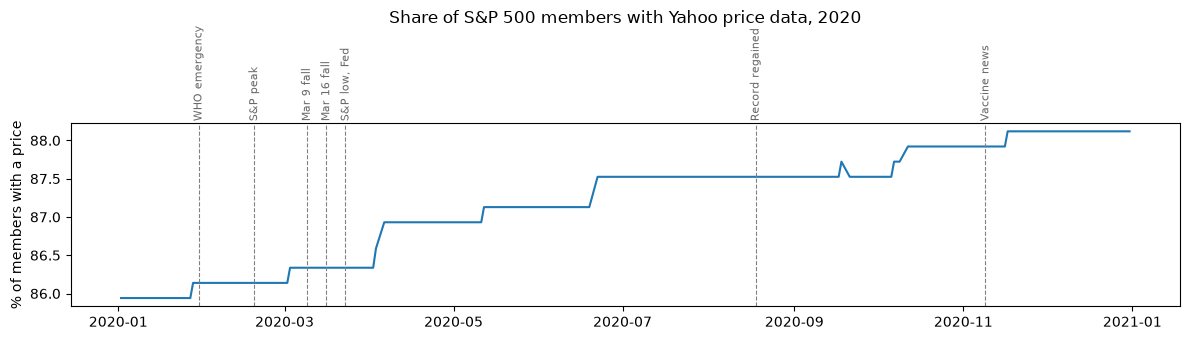

Average share priced, full window:         87.2%
Average share priced, 19 Feb-23 Mar 2020:  86.3%
Lowest daily share: 85.9% on 2020-01-02
Index members per day in window: 505 to 507


In [3]:
cov = px.coverage_by_day(close, membership).loc[START:END]

fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(cov.index, cov["share_priced"] * 100)
ax.set_ylabel("% of members with a price")
ax.set_title("Share of S&P 500 members with Yahoo price data, 2020", pad=TITLE_PAD)
mark_events(ax)
plt.tight_layout(); plt.show()

crash = cov.loc["2020-02-19":"2020-03-23"]
print(f"Average share priced, full window:         {cov['share_priced'].mean():.1%}")
print(f"Average share priced, 19 Feb-23 Mar 2020:  {crash['share_priced'].mean():.1%}")
print(f"Lowest daily share: {cov['share_priced'].min():.1%} on {cov['share_priced'].idxmin().date()}")
print(f"Index members per day in window: {int(cov['n_members'].min())} to {int(cov['n_members'].max())}")

In [4]:
# Members during the window with no or partial price data, ranked by days in the index during the window
win_mem = membership.loc[START:END]
win_has = px_close.loc[START:END].notna() & win_mem
gap = pd.DataFrame({
    "member_days_in_window": win_mem.sum(),
    "priced_days_in_window": win_has.sum(),
})
gap = gap[gap["member_days_in_window"] > 0]
gap["coverage_in_window"] = (gap["priced_days_in_window"] / gap["member_days_in_window"]).round(3)
missing = gap[gap["coverage_in_window"] < 1].sort_values("member_days_in_window", ascending=False)
print(f"{len(missing)} of {len(gap)} window members have incomplete prices; "
      f"{int((gap['priced_days_in_window'] == 0).sum())} have none")
missing.head(30)

72 of 525 window members have incomplete prices; 72 have none


,member_days_in_window,priced_days_in_window,coverage_in_window
ABC,253,0,0.0
ABMD,253,0,0.0
ANSS,253,0,0.0
ALXN,253,0,0.0
ANTM,253,0,0.0
BK,253,0,0.0
AVB,253,0,0.0
ATVI,253,0,0.0
XLNX,253,0,0.0
WRK,253,0,0.0


*Note for the write-up:* look at the tickers above. They are ticker symbols only (the membership file has no company names), so check a few by hand. Record what you find in `docs/survivorship_bias.md`. Unlike 2008, most of these firms did not fail in the crash, so the 2020 stress measures should be less distorted than the 2008 ones, but dispersion and connectedness could still be slightly off if the missing firms behaved differently from the survivors. Renamed survivors such as FB/META are the clearest fixable gap (a ticker alias table would recover them).

In [5]:
# Bad-print check: very large one-day moves on member days. Real moves of this size
# exist (2020 had some), but a price series that jumps and reverses is a data error.
big = rets.loc[START:END].stack().rename("return")
big = big[big.abs() > 0.40].sort_values()
print(f"{len(big)} member-day returns beyond +/-40% in the window")
(big if len(big) <= 10 else pd.concat([big.head(5), big.tail(5)])).to_frame()

7 member-day returns beyond +/-40% in the window


return
date                     
2020-03-09 APA  -0.538647
           OXY  -0.520138
           FANG -0.446458
2020-03-24 DXC   0.410160
2020-06-04 AAL   0.410970
2020-03-24 NCLH  0.421923
2020-11-04 BIIB  0.439739

## 3. Market overview: level, drawdown and volatility

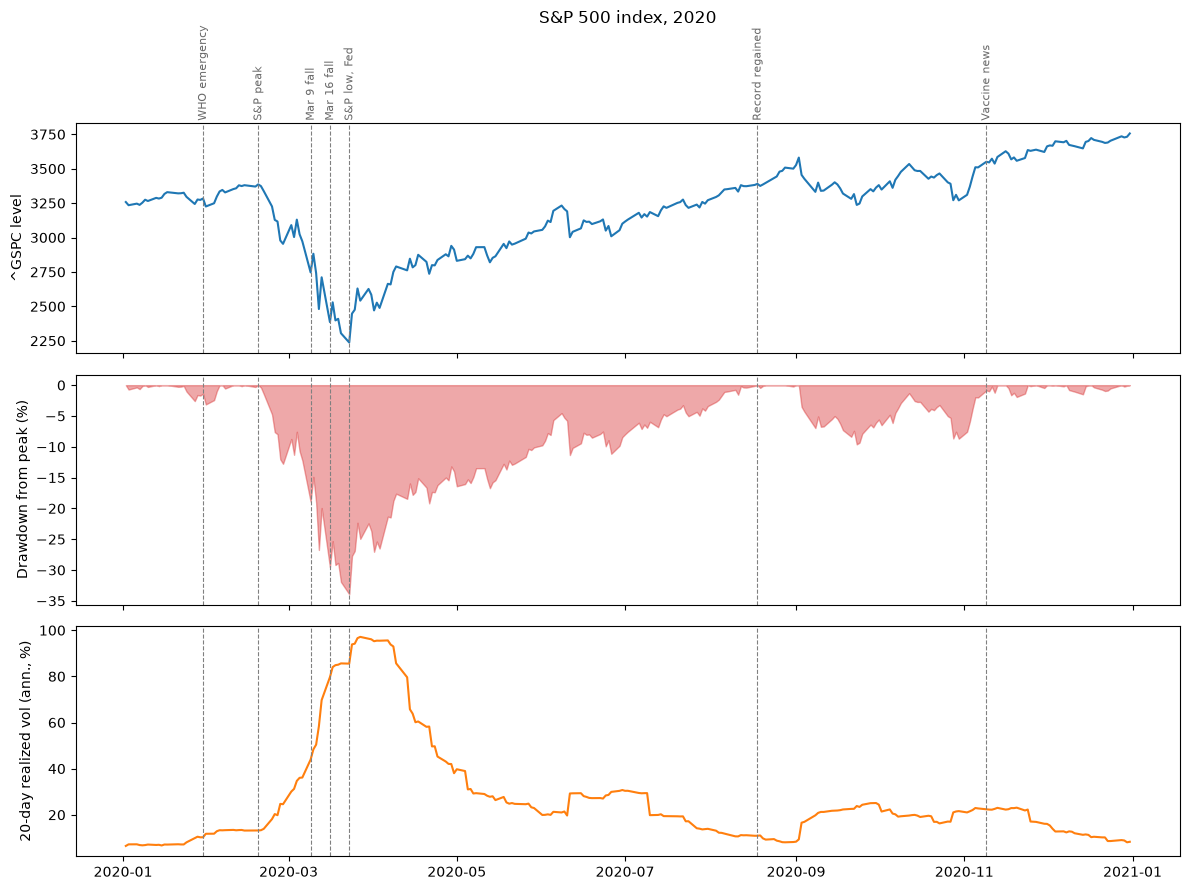

Peak close before the trough: 3,386.15 on 2020-02-19
Trough close in window:       2,237.40 on 2020-03-23
Peak to trough: -33.9% in 23 trading days
Prior peak regained on: 2020-08-18
Highest 20-day realized vol: 97.1% on 2020-03-27
Worst 3 days:  2020-03-16 -12.0%, 2020-03-12 -9.5%, 2020-03-09 -7.6%
Best 3 days:   2020-03-24 +9.4%, 2020-03-13 +9.3%, 2020-04-06 +7.0%


In [6]:
g = gspc.loc[START:END]
drawdown = g / g.cummax() - 1
daily_idx = gspc.pct_change(fill_method=None)
vol20 = daily_idx.rolling(20).std().loc[START:END] * np.sqrt(252)

fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
axes[0].plot(g.index, g); axes[0].set_ylabel("^GSPC level")
axes[1].fill_between(drawdown.index, drawdown * 100, 0, color="tab:red", alpha=0.4)
axes[1].set_ylabel("Drawdown from peak (%)")
axes[2].plot(vol20.index, vol20 * 100, color="tab:orange"); axes[2].set_ylabel("20-day realized vol (ann., %)")
for i, ax in enumerate(axes):
    mark_events(ax, labels=(i == 0))
axes[0].set_title("S&P 500 index, 2020", pad=TITLE_PAD)
plt.tight_layout(); plt.show()

trough_date = g.idxmin()
peak_date = g.loc[:trough_date].idxmax()
after = g.loc[trough_date:]
regained = after[after >= g.loc[peak_date]]
d = daily_idx.loc[START:END]
print(f"Peak close before the trough: {g.loc[peak_date]:,.2f} on {peak_date.date()}")
print(f"Trough close in window:       {g.loc[trough_date]:,.2f} on {trough_date.date()}")
print(f"Peak to trough: {g.loc[trough_date] / g.loc[peak_date] - 1:.1%} in {len(g.loc[peak_date:trough_date]) - 1} trading days")
print(f"Prior peak regained on: {regained.index[0].date() if len(regained) else 'not in window'}")
print(f"Highest 20-day realized vol: {vol20.max():.1%} on {vol20.idxmax().date()}")
print("Worst 3 days: ", ", ".join(f"{i.date()} {v:.1%}" for i, v in d.nsmallest(3).items()))
print("Best 3 days:  ", ", ".join(f"{i.date()} {v:+.1%}" for i, v in d.nlargest(3).items()))

## 4. Sanity check: equal-weighted member portfolio vs the index

The official index is cap-weighted, so the two lines should move together but not match. A large, persistent gap would point to a data problem. Two gaps are expected for known reasons: our stock prices are dividend-adjusted (total return) while ^GSPC is a price index, so the stock line gains roughly the dividend yield (about 1.5% a year) on top; and in 2020 a few very large technology stocks drove the index, which favors the cap-weighted line.

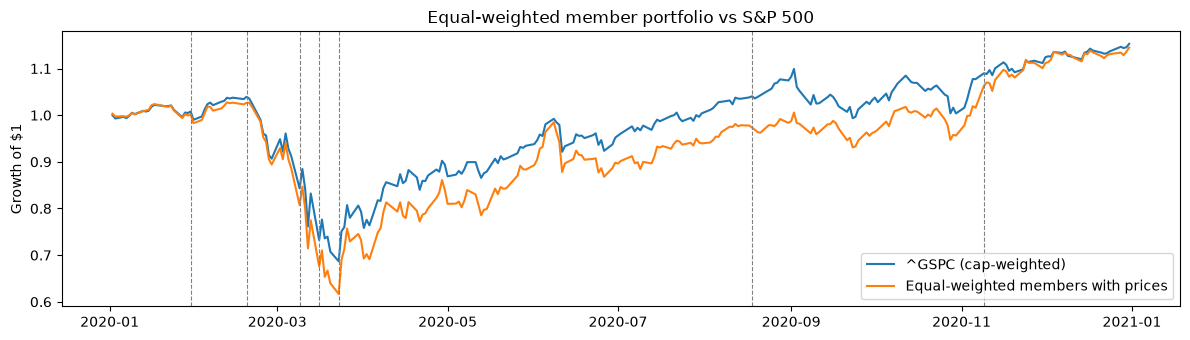

Correlation of daily returns (EW vs ^GSPC): 0.953
Year-end growth of $1: ^GSPC 1.153, equal-weighted 1.145


In [7]:
ew = rets.loc[START:END].mean(axis=1, skipna=True)
ew_level = (1 + ew.fillna(0)).cumprod()
ix_level = g / g.iloc[0]

fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(ix_level.index, ix_level, label="^GSPC (cap-weighted)")
ax.plot(ew_level.index, ew_level, label="Equal-weighted members with prices")
ax.set_ylabel("Growth of $1"); ax.legend(); mark_events(ax, labels=False)
ax.set_title("Equal-weighted member portfolio vs S&P 500")
plt.tight_layout(); plt.show()

daily_corr = ew.corr(daily_idx.loc[START:END])
print(f"Correlation of daily returns (EW vs ^GSPC): {daily_corr:.3f}")
print(f"Year-end growth of $1: ^GSPC {ix_level.iloc[-1]:.3f}, equal-weighted {ew_level.iloc[-1]:.3f}")

## 5. Cross-section: dispersion and breadth

* **Dispersion:** standard deviation of returns across stocks each day. High dispersion means stocks are moving very differently.
* **Breadth:** share of members trading above their own 50-day moving average.

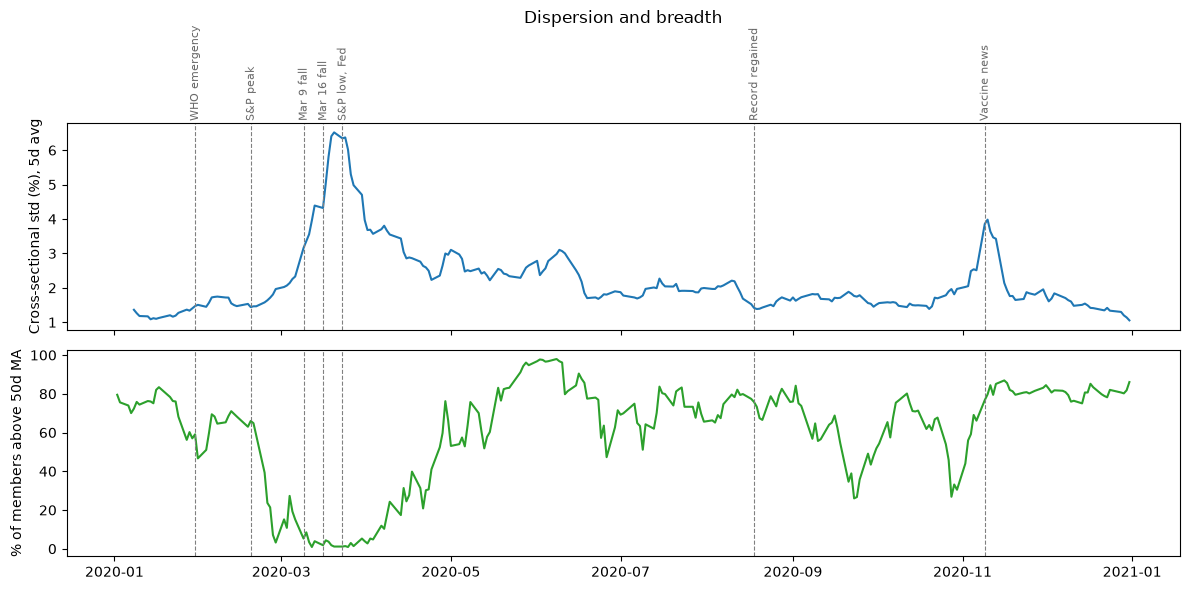

Dispersion (5d avg) peak: 6.52% on 2020-03-20
Breadth low: 0.9% on 2020-03-12; breadth first back above 80%: 2020-05-18


In [8]:
dispersion = rets.loc[START:END].std(axis=1, skipna=True)
ma50 = px_close.rolling(50, min_periods=50).mean()
above = (px_close > ma50).where(membership & ma50.notna())
breadth = above.mean(axis=1, skipna=True).loc[START:END]

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
axes[0].plot(dispersion.index, dispersion.rolling(5).mean() * 100)
axes[0].set_ylabel("Cross-sectional std (%), 5d avg")
axes[1].plot(breadth.index, breadth * 100, color="tab:green")
axes[1].set_ylabel("% of members above 50d MA")
for i, ax in enumerate(axes):
    mark_events(ax, labels=(i == 0))
axes[0].set_title("Dispersion and breadth", pad=TITLE_PAD)
plt.tight_layout(); plt.show()

print(f"Dispersion (5d avg) peak: {dispersion.rolling(5).mean().max():.2%} on {dispersion.rolling(5).mean().idxmax().date()}")
print(f"Breadth low: {breadth.min():.1%} on {breadth.idxmin().date()}; "
      f"breadth first back above 80%: {breadth.loc[breadth.idxmin():][lambda s: s > 0.8].index[0].date()}")

## 6. Connectedness: did stocks start moving together before the worst of the stress?

For every 5th trading day, take the previous 60 trading days of returns for stocks that were members with complete data over that window, and compute:

* **Average pairwise correlation** (the mean of the off-diagonal entries of the correlation matrix)
* **First principal component variance share**: the largest eigenvalue of the correlation matrix divided by the number of stocks. This is a one-component version of the absorption ratio idea in Kritzman et al. (2011); the full absorption ratio is added in Week 4.

The 2020 crash lasted about 23 trading days, so a 60-day window is mostly calm days from before the crash and reacts slowly. We therefore also compute a **20-day** version (same method, shorter window). A short window reacts faster but is noisier and uses fewer observations per stock, so treat the two as a trade-off, not a correction.

This is a first look, not a forecast test.

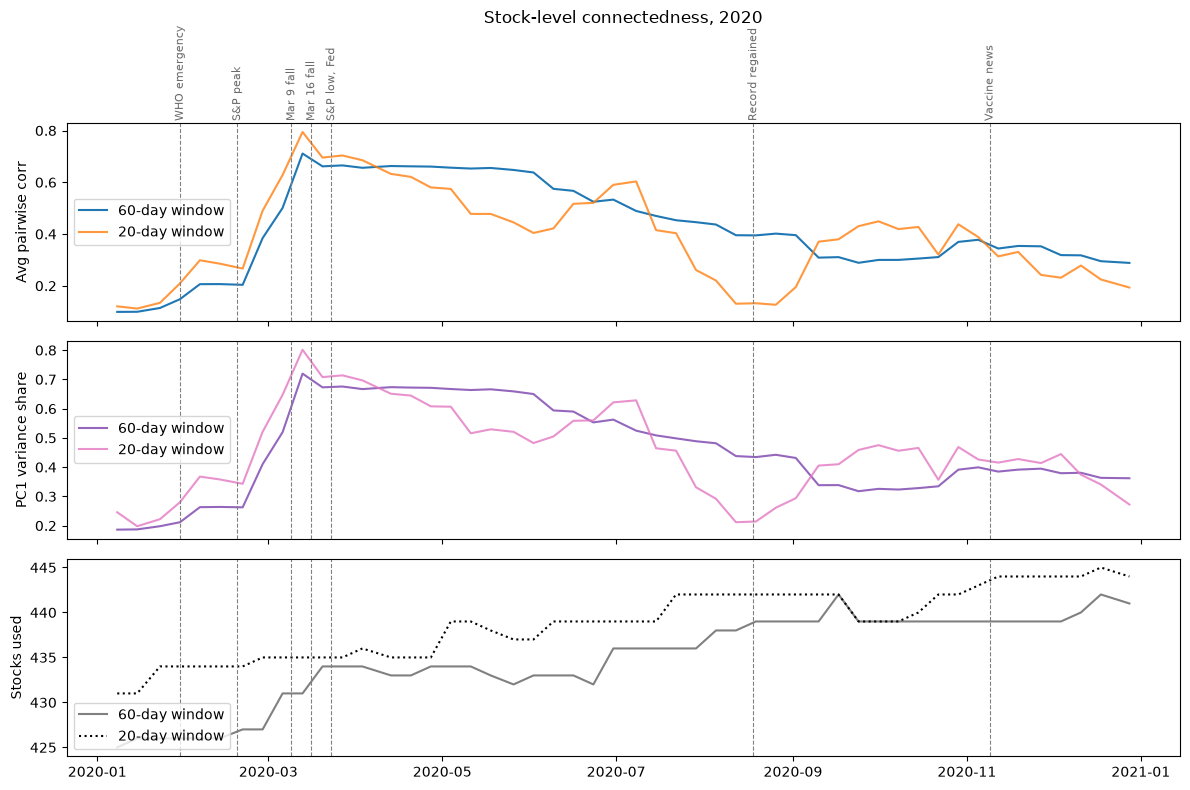

60d avg corr: first value 0.099, peak 0.711 on 2020-03-13
20d avg corr: first value 0.120, peak 0.794 on 2020-03-13
Stocks with complete data per window: 60d 425 to 442, 20d 431 to 445


In [9]:
def connectedness(returns: pd.DataFrame, window: int = 60, step: int = 5, min_stocks: int = 100) -> pd.DataFrame:
    rows = {}
    idx = returns.index
    for end in range(window, len(idx) + 1, step):
        block = returns.iloc[end - window:end]
        block = block.loc[:, block.notna().all()]          # complete data over the window only
        block = block.loc[:, block.std() > 0]
        n = block.shape[1]
        if n < min_stocks:
            continue
        c = np.corrcoef(block.values, rowvar=False)
        avg = (c.sum() - n) / (n * (n - 1))
        top = np.linalg.eigvalsh(c)[-1] / n
        rows[idx[end - 1]] = {"avg_corr": avg, "pc1_share": top, "n_stocks": n}
    return pd.DataFrame(rows).T

conn = connectedness(rets.loc[WARMUP:END]).loc[START:END]
conn20 = connectedness(rets.loc[WARMUP:END], window=20).loc[START:END]

fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
axes[0].plot(conn.index, conn["avg_corr"], label="60-day window")
axes[0].plot(conn20.index, conn20["avg_corr"], label="20-day window", alpha=0.8)
axes[0].set_ylabel("Avg pairwise corr"); axes[0].legend(loc="center left")
axes[1].plot(conn.index, conn["pc1_share"], color="tab:purple", label="60-day window")
axes[1].plot(conn20.index, conn20["pc1_share"], color="tab:pink", label="20-day window", alpha=0.8)
axes[1].set_ylabel("PC1 variance share"); axes[1].legend(loc="center left")
axes[2].plot(conn.index, conn["n_stocks"], color="grey", label="60-day window")
axes[2].plot(conn20.index, conn20["n_stocks"], color="black", ls=":", label="20-day window")
axes[2].set_ylabel("Stocks used"); axes[2].legend(loc="lower left")
for i, ax in enumerate(axes):
    mark_events(ax, labels=(i == 0))
axes[0].set_title("Stock-level connectedness, 2020", pad=TITLE_PAD)
plt.tight_layout(); plt.show()

print(f"60d avg corr: first value {conn['avg_corr'].iloc[0]:.3f}, peak {conn['avg_corr'].max():.3f} on {conn['avg_corr'].idxmax().date()}")
print(f"20d avg corr: first value {conn20['avg_corr'].iloc[0]:.3f}, peak {conn20['avg_corr'].max():.3f} on {conn20['avg_corr'].idxmax().date()}")
print(f"Stocks with complete data per window: 60d {int(conn['n_stocks'].min())} to {int(conn['n_stocks'].max())}, "
      f"20d {int(conn20['n_stocks'].min())} to {int(conn20['n_stocks'].max())}")

### Optional: compare with the St. Louis Fed Financial Stress Index and the VIX

Runs only if `daily_panel.parquet` from `01_data_collection.ipynb` exists. The stress index is weekly; this notebook forward-fills it onto trading days by observation date, which is fine for EDA but **not** for modeling (release lag, see the note in `01_data_collection.ipynb`). The VIX is daily and is known at the close of each day.

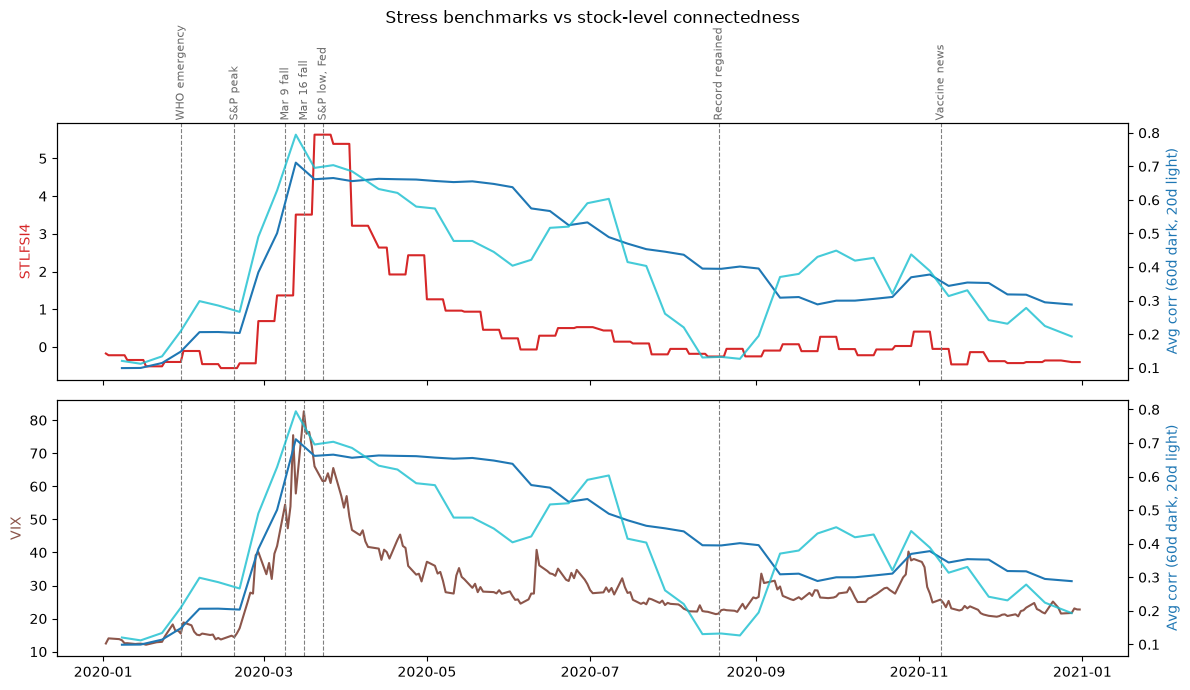

In [10]:
panel_path = PROC / "daily_panel.parquet"
panel = pd.read_parquet(panel_path) if panel_path.exists() else None

def from_panel(col):
    if panel is None or col not in panel:
        return None
    return panel[col].ffill().reindex(close.index, method="ffill")

stl, vix = from_panel("STLFSI4"), from_panel("VIXCLS")

if stl is None and vix is None:
    print("daily_panel.parquet not found; run 01_data_collection.ipynb to add this comparison.")
else:
    fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
    for ax1, s, name, color in [(axes[0], stl, "STLFSI4", "tab:red"), (axes[1], vix, "VIX", "tab:brown")]:
        if s is None:
            continue
        s = s.loc[START:END]
        ax1.plot(s.index, s, color=color); ax1.set_ylabel(name, color=color)
        ax2 = ax1.twinx()
        ax2.plot(conn.index, conn["avg_corr"], color="tab:blue")
        ax2.plot(conn20.index, conn20["avg_corr"], color="tab:cyan", alpha=0.8)
        ax2.set_ylabel("Avg corr (60d dark, 20d light)", color="tab:blue")
        mark_events(ax1, labels=(name == "STLFSI4"))
    axes[0].set_title("Stress benchmarks vs stock-level connectedness", pad=TITLE_PAD)
    plt.tight_layout(); plt.show()

## 7. Timing table: when did each measure first get unusual?

For each measure, the first date in the window when it exceeded its 2019 (calm baseline, 2019-04-01 to 2019-12-31) mean by 2 standard deviations, plus the date of its peak. The "trading days vs S&P peak" column counts trading days from the S&P 500 peak (2020-02-19): a negative number means the measure fired *before* the index peaked. The connectedness measures are computed here for **every** trading day (the charts above use every 5th day to keep the loop fast), so all measures in the table have daily resolution. This is a rough way to compare timing, not a formal lead-time test (that comes in Week 6 with labeled stress periods). The 2-standard-deviation rule is an arbitrary EDA choice, and a threshold crossed once says nothing about false alarms: check how often each measure crossed its threshold in 2019 too.

In [11]:
conn_full = connectedness(rets.loc[WARMUP:END], step=1)
conn20_full = connectedness(rets.loc[WARMUP:END], window=20, step=1)
vol20_full = daily_idx.rolling(20).std() * np.sqrt(252)
disp_full = rets.std(axis=1, skipna=True).rolling(5).mean()

measures = {
    "20d realized vol": vol20_full,
    "dispersion (5d avg)": disp_full,
    "avg pairwise corr (60d)": conn_full["avg_corr"],
    "avg pairwise corr (20d)": conn20_full["avg_corr"],
    "PC1 variance share (60d)": conn_full["pc1_share"],
    "PC1 variance share (20d)": conn20_full["pc1_share"],
}
if stl is not None:
    measures["STLFSI4 (weekly, by observation date)"] = stl
if vix is not None:
    measures["VIX"] = vix

cal = close.loc[START:END].index
peak_pos = cal.get_loc(peak_date)
rows = {}
for name, s in measures.items():
    s = s.astype(float)
    base = s.loc[BASE0:BASE1].dropna()
    thr = base.mean() + 2 * base.std()
    w = s.loc[START:END].dropna()
    hit = w[w > thr]
    first = hit.index[0] if len(hit) else None
    rows[name] = {
        "2019 baseline mean": round(base.mean(), 4),
        "threshold (mean + 2 sd)": round(thr, 4),
        "days above threshold in baseline": int((base > thr).sum()),
        "first date above threshold": first.date() if first is not None else None,
        "trading days vs S&P peak": (cal.get_loc(first) - peak_pos) if first is not None else None,
        "peak date": w.idxmax().date(),
    }
timing = pd.DataFrame(rows).T

ref = {f"S&P 500 down {int(x * 100)}% from its peak": drawdown[drawdown <= -x].index[0].date()
       for x in (0.05, 0.10, 0.20)}
print("Reference dates:", ref)
timing

Reference dates: {'S&P 500 down 5% from its peak': datetime.date(2020, 2, 25), 'S&P 500 down 10% from its peak': datetime.date(2020, 2, 27), 'S&P 500 down 20% from its peak': datetime.date(2020, 3, 12)}


,2019 baseline mean,threshold (mean + 2 sd),days above threshold in baseline,first date above threshold,trading days vs S&P peak,peak date
20d realized vol,0.1146,0.2074,14,2020-02-27,6,2020-03-27
dispersion (5d avg),0.0137,0.0189,5,2020-02-28,7,2020-03-20
avg pairwise corr (60d),0.2648,0.3908,0,2020-03-02,8,2020-03-16
avg pairwise corr (20d),0.261,0.5145,10,2020-03-02,8,2020-03-16
PC1 variance share (60d),0.3065,0.4175,1,2020-03-02,8,2020-03-16
PC1 variance share (20d),0.3345,0.5447,11,2020-03-02,8,2020-03-16
"STLFSI4 (weekly, by observation date)",-0.2358,0.2894,5,2020-02-28,7,2020-03-20
VIX,15.0423,20.0279,9,2020-02-24,3,2020-03-16


## 8. Robustness: does a fixed, survivor-style panel change the connectedness picture?

Section 6 uses a rolling universe: whichever stocks were members with data in each 60-day window. Here we recompute it using only stocks that were members **and** had a price on **every** trading day of 2020. That fixed panel is what a survivorship-biased dataset would give us. If the two lines differ a lot, our network results are sensitive to how we handle index changes and missing firms. (Unlike Section 6, the fixed panel uses unmasked returns, so the stocks' own pre-2020 prices are included in the early windows.)

Fixed panel: 426 stocks present and priced on all 253 trading days


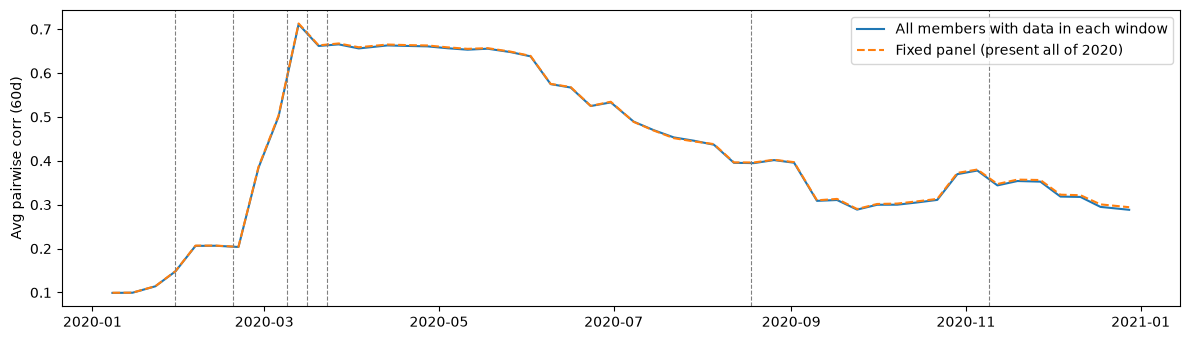

Max absolute difference in avg corr: 0.0059
Mean difference (all members minus fixed panel): -0.0016


In [12]:
n_days = len(win_mem)
fixed = gap.index[(gap["member_days_in_window"] == n_days) & (gap["priced_days_in_window"] == n_days)]
print(f"Fixed panel: {len(fixed)} stocks present and priced on all {n_days} trading days")
conn_full_cov = connectedness(rets_all.loc[WARMUP:END, fixed]).loc[START:END]

fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(conn.index, conn["avg_corr"], label="All members with data in each window")
ax.plot(conn_full_cov.index, conn_full_cov["avg_corr"], label="Fixed panel (present all of 2020)", ls="--")
ax.set_ylabel("Avg pairwise corr (60d)"); ax.legend(); mark_events(ax, labels=False)
plt.tight_layout(); plt.show()

both = pd.concat([conn["avg_corr"].rename("all_members"), conn_full_cov["avg_corr"].rename("fixed_panel")], axis=1).dropna()
print(f"Max absolute difference in avg corr: {(both['all_members'] - both['fixed_panel']).abs().max():.4f}")
print(f"Mean difference (all members minus fixed panel): {(both['all_members'] - both['fixed_panel']).mean():+.4f}")

## 9. Observations

Written from the run on data downloaded 2026-10-27. Re-check the numbers if the data is refreshed. Each point describes what the charts and tables show for this one episode; none of it shows that any measure predicts stress.

1. **Data coverage:** 87.2% of index members had a price on an average day in 2020 (86.3% between the 19 Feb peak and the 23 Mar low; never below 85.9%). 72 of the 525 firms that were members at some point in 2020 have no usable prices, against 60.8% coverage for the 2008 window in `eda_2008.ipynb`. The gaps are firms acquired or delisted after 2020 (for example ATVI, XLNX, CERN, ALXN) and survivors that only changed ticker: FB to META, ANTM to ELV and BK to BNY were checked (Yahoo has full history under the new symbol), and ABC, BLL, COG and FLT in the table above are likely renames too. Check the rest by hand; the split between acquired and renamed has not been counted. Five of the 72 (AVB, EA, EQR, LEG, QRVO) have only a stub of Yahoo history (fewer than 20 rows), not real history; `stub_history` in the coverage report flags these. The bad-print check found 7 daily moves beyond +/-40% on member days. None is undone by an offsetting move the next day, which is what a bad price would look like (next-day returns run from -7.5% to +23.3%), and the three largest falls are oil producers (APA, OXY, FANG) on 9 March, so they look like real moves.
2. **Timing of stress:** the S&P 500 closed at 3,386.15 on 19 Feb and 2,237.40 on 23 Mar, down 33.9% in 23 trading days. It was down 5% by 25 Feb, 10% by 27 Feb and 20% on 12 Mar. The worst day was 16 Mar (-12.0%), then 12 Mar (-9.5%) and 9 Mar (-7.6%). 20-day realized volatility peaked at 97.1% on 27 Mar. The prior peak was regained on 18 Aug.
3. **Connectedness:** average pairwise correlation rose from a 2019 baseline mean of 0.26 to a peak of 0.71 (60-day window) or 0.79 (20-day window) in mid-March, and the first-principal-component share moved with it. On a daily grid every connectedness measure first crossed its mean + 2 sd threshold on 2 Mar, 8 trading days *after* the S&P peak and after VIX (24 Feb), realized volatility (27 Feb), dispersion and the St. Louis stress index (both 28 Feb, the latter by observation date). So in 2020 connectedness rose during the fall, not before the index peaked, and it did not lead the simple volatility measures. One episode and one arbitrary threshold: do not generalize.
4. **Cross-section:** dispersion (5-day average) peaked at 6.5% on 20 Mar, a few days after the worst index days (9, 12 and 16 Mar). Breadth hit 0.9% on 12 Mar (almost no stock above its 50-day average) and was back above 80% on 18 May. The equal-weighted member portfolio and the index have a daily return correlation of 0.95 (0.99 in 2008), and ended the year within 1 percentage point of each other (1.145 vs 1.153), with the dividend-adjustment caveat in Section 4.
5. **Robustness:** restricting to the 426 stocks present and priced on all 253 trading days changes the 60-day average correlation by at most 0.006 (mean -0.002), so survivorship in the price panel does not change the 2020 connectedness picture. This is a weaker test than it sounds: the fixed panel is itself drawn from survivors that Yahoo still lists.
6. **Implications for the model:**
   * A 60-day window is longer than the crash (23 trading days) but gave the same first-crossing date as the 20-day window. The 20-day measure is noisier when markets are calm: in the 2019 baseline it exceeds its own threshold on 10 days (average correlation) and 11 days (PC1 share), against 0 and 1 days for the 60-day measure. Treat window length as a trade-off to test, not settle.
   * VIX and realized volatility fired first, so they are the bar to beat. Whether connectedness adds information beyond them needs the labeled-episode test planned for Week 6.
   * The stress index first crossing on 28 Feb is by observation date. It is published after the week it describes, so its real-time signal would come later: shift it by the release lag before using it as a model input.
   * Data: a small ticker alias table (FB to META and similar) would recover renamed survivors. For 2008 the price panel covers only about 61% of members, so any 2008 result should carry that caveat.

## Save outputs for the team

In [13]:
out = PROC / "eda_2020"
out.mkdir(parents=True, exist_ok=True)
conn.to_csv(out / "connectedness_60d.csv")
conn20.to_csv(out / "connectedness_20d.csv")
cov.to_csv(out / "coverage_by_day.csv")
missing.to_csv(out / "members_missing_prices.csv")
timing.to_csv(out / "timing_table.csv")
print("Saved to", out.relative_to(ROOT))

Saved to data/processed/eda_2020
